# 🔬 Real-World Stress Test Series — Episode 03
## Operations & Supply Chain: Can observed sales hide unmet demand?

**Research question:** When sales fall to zero during a simulated stockout, would a simple forecasting baseline interpret the missing sales as lower demand?

### Important design choice
The Olist public e-commerce dataset does **not** contain reliable item-level inventory availability or true lost-demand labels. Therefore, this notebook uses Olist to build an **order-activity proxy**, then creates a clearly labelled **synthetic stockout scenario**. It does not claim to recover true demand or prove what customers would have purchased.

The analysis is a focused stress test experiment, not a production demand forecasting system.

## 1. What this notebook will do

1. Load the Olist orders and order-items tables from public raw CSV URLs.
2. Check data quality and identify delivered orders.
3. Aggregate delivered order items into daily observed item-level sales for a manageable set of frequently sold products.
4. Create a daily time series with zero-sales days filled in.
5. Train a simple moving-average baseline using pre-test observations only.
6. Simulate a 14-day stockout by masking observed sales as zero for one selected product during a test period.
7. Compare baseline forecasts with observed sales and show how zeros can distort a naïve interpretation.
8. Save figures and summary tables for the LinkedIn post.

**No model accuracy claim will be made for the simulated stockout period.** The true lost demand during a stockout is unknown.

## 2. Dataset and source

Dataset: **Brazilian E-Commerce Public Dataset by Olist** (Kaggle).

The notebook downloads the `orders` and `order_items` CSV files from a public mirror so it can run without a Kaggle API token. Public mirrors can change or become unavailable; if a URL fails, download the dataset from Kaggle and update the URLs in the next cell.

Source page: https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce

The source dataset is third-party data. Follow the dataset publisher's terms and attribution requirements.

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Find the repository root
CURRENT_DIR = Path.cwd()

if (CURRENT_DIR / "Data" / "Raw").exists():
    PROJECT_ROOT = CURRENT_DIR
elif (CURRENT_DIR.parent / "Data" / "Raw").exists():
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    raise FileNotFoundError(
        "Cannot find Data/Raw. Check your repository folder location."
    )

# Correct paths
DATA_DIR = PROJECT_ROOT / "Data" / "Raw"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
RESULTS_DIR = PROJECT_ROOT / "outputs" / "results"

# Create output folders only at the repository root
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Repository root:", PROJECT_ROOT)
print("Dataset folder:", DATA_DIR)
print("Figures folder:", FIGURES_DIR)
print("Results folder:", RESULTS_DIR)

Repository root: c:\Users\VICTUS\OneDrive\Documents\GitHub\Olist-E-Commerce-Stockout-Stress-Test
Dataset folder: c:\Users\VICTUS\OneDrive\Documents\GitHub\Olist-E-Commerce-Stockout-Stress-Test\Data\Raw
Figures folder: c:\Users\VICTUS\OneDrive\Documents\GitHub\Olist-E-Commerce-Stockout-Stress-Test\outputs\figures
Results folder: c:\Users\VICTUS\OneDrive\Documents\GitHub\Olist-E-Commerce-Stockout-Stress-Test\outputs\results


## 3. Load the Data

This project uses two Olist files:

- `olist_orders_dataset.csv`: order timestamps and order statuses.
- `olist_order_items_dataset.csv`: products associated with each order.

The files are joined using `order_id`.

In [3]:
orders_path = DATA_DIR / "olist_orders_dataset.csv"
items_path = DATA_DIR / "olist_order_items_dataset.csv"

print("Orders file exists:", orders_path.exists())
print("Order items file exists:", items_path.exists())

if not orders_path.exists() or not items_path.exists():
    raise FileNotFoundError(
        "Dataset files not found. Check that both CSV files are inside Data/Raw."
    )

orders = pd.read_csv(orders_path, low_memory=False)
order_items = pd.read_csv(items_path, low_memory=False)

print("Orders shape:", orders.shape)
print("Order items shape:", order_items.shape)

display(orders.head())
display(order_items.head())

Orders file exists: True
Order items file exists: True
Orders shape: (99441, 8)
Order items shape: (112650, 7)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


## 4. Initial Data Inspection

Before preparing the time series, inspect the dataset structure,
missing values, duplicate records and order-status distribution.

In [4]:
print("Orders columns:")
print(orders.columns.tolist())

print("\nOrder-item columns:")
print(order_items.columns.tolist())

print("\nOrder statuses:")
print(orders["order_status"].value_counts(dropna=False))

print("\nMissing values in orders:")
display(orders.isna().sum().sort_values(ascending=False))

print("\nMissing values in order items:")
display(order_items.isna().sum().sort_values(ascending=False))

print("\nDuplicate order IDs in orders:", orders["order_id"].duplicated().sum())

print(
    "Duplicate order-item keys:",
    order_items.duplicated(subset=["order_id", "order_item_id"]).sum()
)

Orders columns:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

Order-item columns:
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

Order statuses:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Missing values in orders:


order_delivered_customer_date    2965
order_delivered_carrier_date     1783
order_approved_at                 160
order_id                            0
order_purchase_timestamp            0
order_status                        0
customer_id                         0
order_estimated_delivery_date       0
dtype: int64


Missing values in order items:


order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64


Duplicate order IDs in orders: 0
Duplicate order-item keys: 0


## 5. Data Preparation

Convert the purchase timestamp to a datetime value, keep delivered
orders for the main analysis, and join the order records with their
order-item records.

The resulting table represents item lines belonging to delivered
orders. It does not provide a verified count of units demanded or
units that could not be purchased.

In [5]:
# Parse the purchase timestamp
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    errors="coerce"
)

# Remove records without the key fields needed for this analysis
orders_clean = orders.dropna(
    subset=["order_id", "order_purchase_timestamp", "order_status"]
).copy()

items_clean = order_items.dropna(
    subset=["order_id", "product_id"]
).copy()

# Retain delivered orders
delivered_orders = orders_clean[
    orders_clean["order_status"] == "delivered"
].copy()

# Join orders to order items
sales = delivered_orders[
    ["order_id", "order_purchase_timestamp"]
].merge(
    items_clean[["order_id", "order_item_id", "product_id"]],
    on="order_id",
    how="inner",
    validate="one_to_many"
)

# Use the calendar day of purchase
sales["purchase_date"] = (
    sales["order_purchase_timestamp"].dt.floor("D")
)

print("Delivered orders:", len(delivered_orders))
print("Joined item records:", len(sales))
print("Date range:", sales["purchase_date"].min(), "to", sales["purchase_date"].max())

display(sales.head())

Delivered orders: 96478
Joined item records: 110197
Date range: 2016-09-15 00:00:00 to 2018-08-29 00:00:00


,order_id,order_purchase_timestamp,order_item_id,product_id,purchase_date
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,1,87285b34884572647811a353c7ac498a,2017-10-02
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,1,595fac2a385ac33a80bd5114aec74eb8,2018-07-24
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,1,aa4383b373c6aca5d8797843e5594415,2018-08-08
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,1,d0b61bfb1de832b15ba9d266ca96e5b0,2017-11-18
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,1,65266b2da20d04dbe00c5c2d3bb7859e,2018-02-13


## 6. Build the Daily Time Series

Select the product with the largest number of delivered-order item
records. Count its item records per calendar day and fill dates with
no recorded item activity with zero.

These counts are a proxy for sales activity, not verified unit demand.

In [6]:
# Rank products by number of delivered-order item records
product_counts = sales["product_id"].value_counts()

if product_counts.empty:
    raise ValueError(
        "No delivered order-item records were found. "
        "Check the files and column names."
    )

selected_product = product_counts.index[0]

print("Selected product:", selected_product)
print("Delivered item-record count:", product_counts.iloc[0])

# Filter to the selected product
product_sales = sales[
    sales["product_id"] == selected_product
].copy()

# Count item records per day
daily_sales = (
    product_sales.groupby("purchase_date")
    .size()
    .sort_index()
)

# Include all calendar days between the first and last observed dates
full_dates = pd.date_range(
    start=daily_sales.index.min(),
    end=daily_sales.index.max(),
    freq="D"
)

daily_sales = daily_sales.reindex(full_dates, fill_value=0)
daily_sales.index.name = "date"
daily_sales.name = "observed_item_records"

print("Number of calendar days:", len(daily_sales))
print("Days with zero recorded item activity:", (daily_sales == 0).sum())

display(daily_sales.head(10).to_frame())

Selected product: aca2eb7d00ea1a7b8ebd4e68314663af
Delivered item-record count: 520
Number of calendar days: 390
Days with zero recorded item activity: 219


,observed_item_records
date,
2017-07-25,1
2017-07-26,0
2017-07-27,0
2017-07-28,2
2017-07-29,2
2017-07-30,0
2017-07-31,0
2017-08-01,3
2017-08-02,1


## 7. Historical Sales Activity

Plot the daily item-record counts for the selected product.

This helps identify periods of high activity, low activity and
days with zero recorded sales activity before simulating a stress event.

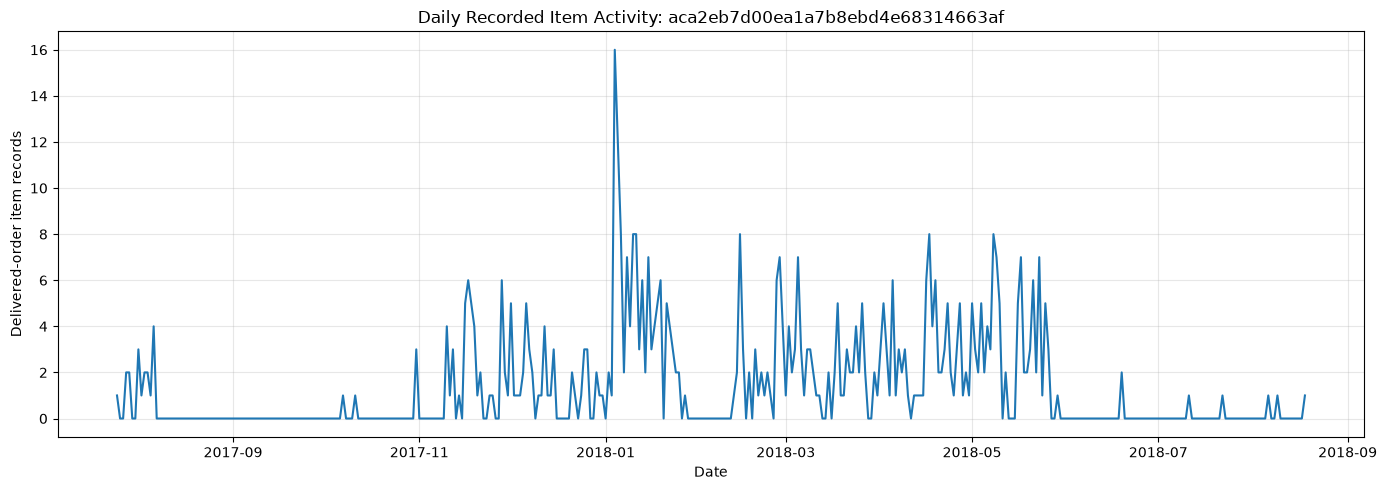

In [7]:
plt.figure(figsize=(14, 5))
plt.plot(daily_sales.index, daily_sales.values)
plt.title(f"Daily Recorded Item Activity: {selected_product}")
plt.xlabel("Date")
plt.ylabel("Delivered-order item records")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "historical_observed_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 8. Define a chronological train/test split

We use an early period for fitting the simple baseline and reserve the later period for the stress experiment. This avoids randomly mixing future and past observations.

Use the earliest 80% of dates as the training period and the latest
20% as the test period.

A chronological split preserves the order of time. Random splitting
is not appropriate for this forecasting experiment.

The baseline is a simple trailing 7 day moving average. It is intentionally transparent; this is a demonstration of the measurement problem, not a competition to build the best forecaster.

In [8]:
split_idx = int(len(daily_sales) * 0.80)

if split_idx < 7 or len(daily_sales) - split_idx < 22:
    raise ValueError(
        "The time series is too short for a 7-day forecast window "
        "and a 14-day stress scenario. Check the selected product."
    )

train = daily_sales.iloc[:split_idx]
test = daily_sales.iloc[split_idx:]

print("Training dates:", train.index.min(), "to", train.index.max())
print("Test dates:", test.index.min(), "to", test.index.max())
print("Training observations:", len(train))
print("Test observations:", len(test))

Training dates: 2017-07-25 00:00:00 to 2018-06-01 00:00:00
Test dates: 2018-06-02 00:00:00 to 2018-08-18 00:00:00
Training observations: 312
Test observations: 78


## 9. Build a simple baseline forecast

The forecast for each test day is the mean of the previous 7 days of **observed** sales. After a simulated stockout, a naïve rolling forecast may be pulled down by the artificial zeros. This is the mechanism we will examine.

For a real inventory system, the model should distinguish unavailable inventory from genuine zero demand.

In [9]:
def rolling_mean_forecast(observed, window=7):
    """
    Produce one-step-ahead forecasts using the previous `window`
    observed values.

    The forecast for date t uses values strictly before date t.
    """
    observed = pd.Series(observed).astype(float)

    forecasts = pd.Series(
        np.nan,
        index=observed.index,
        dtype=float,
        name="forecast"
    )

    for i in range(window, len(observed)):
        forecasts.iloc[i] = observed.iloc[i-window:i].mean()

    return forecasts


baseline_forecast = rolling_mean_forecast(daily_sales, window=7)

display(
    pd.DataFrame({
        "observed_item_records": daily_sales,
        "baseline_forecast": baseline_forecast
    }).tail(12)
)

,observed_item_records,baseline_forecast
date,,
2018-08-07,0,0.142857
2018-08-08,0,0.142857
2018-08-09,1,0.142857
2018-08-10,0,0.285714
2018-08-11,0,0.285714
2018-08-12,0,0.285714
2018-08-13,0,0.285714
2018-08-14,0,0.142857
2018-08-15,0,0.142857


## 10. Simulate a 14-day stockout

create an artificial stockout window in the test period and mask the selected product's observed sales as zero. The stockout window is chosen away from the beginning/end of the test set.

**Critical limitation:** Olist does not provide inventory availability for this product/date series. The stockout dates are simulated and must never be described as a real stockout event.

In [10]:
# Start the scenario after the first seven days of the test period
stockout_start_idx = split_idx + 7
stockout_end_idx = min(stockout_start_idx + 14, len(daily_sales))

stockout_dates = daily_sales.index[
    stockout_start_idx:stockout_end_idx
]

if len(stockout_dates) != 14:
    raise ValueError("Could not create a full 14-day stress window.")

# Preserve the original data and create a separate scenario
stress_sales = daily_sales.copy()
stress_sales.loc[stockout_dates] = 0

print("Simulated stress period:", stockout_dates.min(), "to", stockout_dates.max())
print("Number of days:", len(stockout_dates))
print("Original values during the window:")
display(daily_sales.loc[stockout_dates].to_frame())

print("Stress-scenario values during the window:")
display(stress_sales.loc[stockout_dates].to_frame())

Simulated stress period: 2018-06-09 00:00:00 to 2018-06-22 00:00:00
Number of days: 14
Original values during the window:


,observed_item_records
date,
2018-06-09,0
2018-06-10,0
2018-06-11,0
2018-06-12,0
2018-06-13,0
2018-06-14,0
2018-06-15,0
2018-06-16,0
2018-06-17,0


Stress-scenario values during the window:


,observed_item_records
date,
2018-06-09,0
2018-06-10,0
2018-06-11,0
2018-06-12,0
2018-06-13,0
2018-06-14,0
2018-06-15,0
2018-06-16,0
2018-06-17,0


## 11. Forecast Comparison

Generate a rolling-average forecast from the original observations
and another from the zero-masked stress-scenario observations.

Compare both forecasts over the test period. The difference shows
how the artificial zero values influence subsequent predictions.

In [11]:
stress_forecast = rolling_mean_forecast(stress_sales, window=7)

comparison = pd.DataFrame({
    "actual_recorded_activity": daily_sales,
    "stress_scenario_activity": stress_sales,
    "baseline_forecast": baseline_forecast,
    "stress_forecast": stress_forecast
})

comparison["forecast_difference"] = (
    comparison["stress_forecast"] - comparison["baseline_forecast"]
)

test_comparison = comparison.iloc[split_idx:].copy()

display(test_comparison.head(20))

,actual_recorded_activity,stress_scenario_activity,baseline_forecast,stress_forecast,forecast_difference
date,,,,,
2018-06-02,0,0,0.571429,0.571429,0.000000
2018-06-03,0,0,0.142857,0.142857,0.000000
2018-06-04,0,0,0.142857,0.142857,0.000000
2018-06-05,0,0,0.142857,0.142857,0.000000
2018-06-06,0,0,0.000000,0.000000,0.000000
2018-06-07,0,0,0.000000,0.000000,0.000000
2018-06-08,0,0,0.000000,0.000000,0.000000
2018-06-09,0,0,0.000000,0.000000,0.000000
2018-06-10,0,0,0.000000,0.000000,0.000000


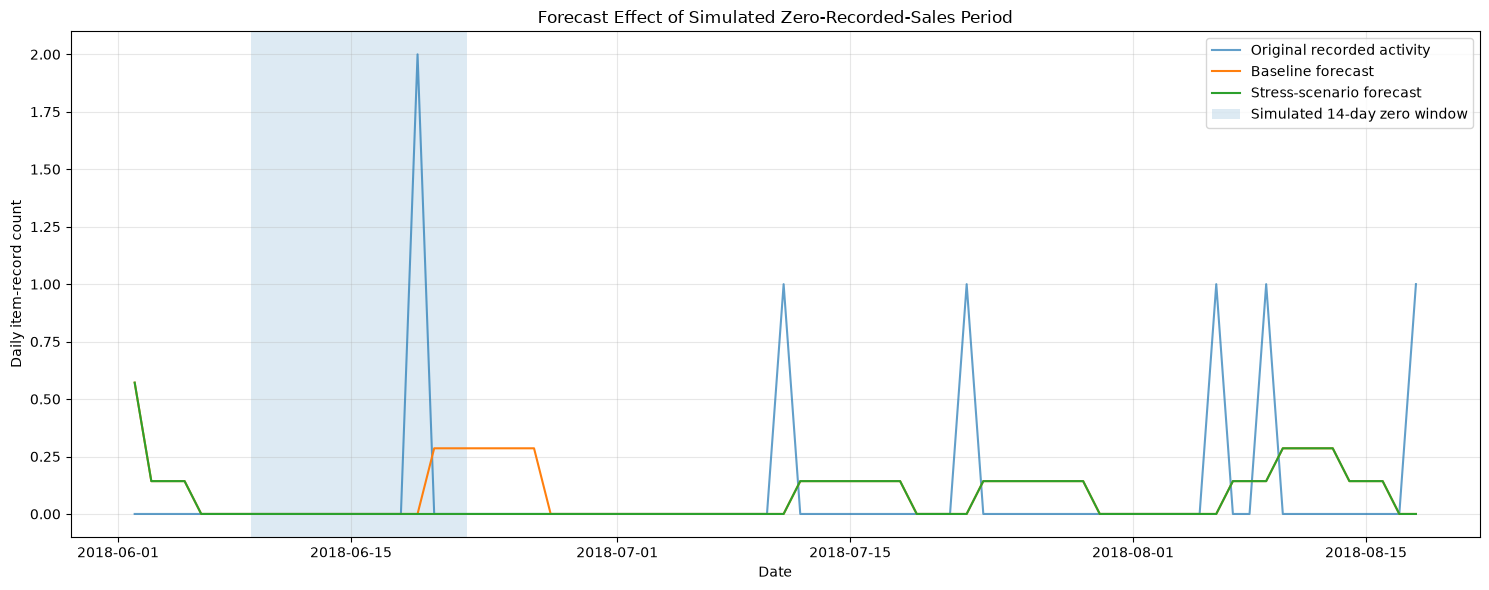

In [12]:
plt.figure(figsize=(15, 6))

plt.plot(
    test_comparison.index,
    test_comparison["actual_recorded_activity"],
    label="Original recorded activity",
    alpha=0.7
)

plt.plot(
    test_comparison.index,
    test_comparison["baseline_forecast"],
    label="Baseline forecast"
)

plt.plot(
    test_comparison.index,
    test_comparison["stress_forecast"],
    label="Stress-scenario forecast"
)

plt.axvspan(
    stockout_dates.min(),
    stockout_dates.max(),
    alpha=0.15,
    label="Simulated 14-day zero window"
)

plt.title("Forecast Effect of Simulated Zero-Recorded-Sales Period")
plt.xlabel("Date")
plt.ylabel("Daily item-record count")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "forecast_effect_of_stockout.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 12. Product Sensitivity Analysis

Repeat the zero-masking experiment for the five products with the
largest numbers of delivered-order item records.

Use the same dates and forecast window for each product to make
the results more comparable.

This is a small sensitivity check, not proof that the results
generalise to all products or sellers.

In [16]:

top_products = product_counts.head(5).index.tolist()
sensitivity_results = []

# Last date of the simulated zero-sales window
stockout_end = stockout_dates.max()

for product_id in top_products:
    product_data = sales[sales["product_id"] == product_id]

    product_daily = (
        product_data.groupby("purchase_date")
        .size()
        .reindex(full_dates, fill_value=0)
    )

    product_daily.index.name = "date"

    # Apply the same simulated window
    product_stress = product_daily.copy()
    product_stress.loc[stockout_dates] = 0

    product_baseline_forecast = rolling_mean_forecast(
        product_daily, window=7
    )

    product_stress_forecast = rolling_mean_forecast(
        product_stress, window=7
    )

    # Evaluate over the same test period and dates
    product_eval = pd.DataFrame({
        "actual": product_daily,
        "baseline": product_baseline_forecast,
        "stress": product_stress_forecast
    }).iloc[split_idx:].dropna()

    product_eval["baseline_error"] = (
        product_eval["baseline"] - product_eval["actual"]
    ).abs()

    product_eval["stress_error"] = (
        product_eval["stress"] - product_eval["actual"]
    ).abs()

    # Forecasts during the simulated zero-sales window
    during = product_eval.loc[
        product_eval.index.isin(stockout_dates)
    ]

    # Forecasts after the simulated window
    after = product_eval.loc[
        product_eval.index > stockout_end
    ]

    sensitivity_results.append({
        "product_id": product_id,
        "delivered_item_records": int(product_counts.loc[product_id]),

        "baseline_test_mae": product_eval["baseline_error"].mean(),
        "stress_test_mae": product_eval["stress_error"].mean(),

        "baseline_mean_forecast_during_window":
            during["baseline"].mean(),

        "stress_mean_forecast_during_window":
            during["stress"].mean(),

        "forecast_change_during_window": (
            during["stress"].mean() - during["baseline"].mean()
        ),

        "baseline_mean_forecast_after_window":
            after["baseline"].mean(),

        "stress_mean_forecast_after_window":
            after["stress"].mean(),

        "forecast_change_after_window": (
            after["stress"].mean() - after["baseline"].mean()
        )
    })

# Create and display the results table
sensitivity_df = pd.DataFrame(sensitivity_results)

display(sensitivity_df.round(3))

# Save the results
sensitivity_df.to_csv(
    RESULTS_DIR / "product_sensitivity_check.csv",
    index=False
)

print("Sensitivity results saved successfully.")


,product_id,delivered_item_records,baseline_test_mae,stress_test_mae,baseline_mean_forecast_during_window,stress_mean_forecast_during_window,forecast_change_during_window,baseline_mean_forecast_after_window,stress_mean_forecast_after_window,forecast_change_after_window
0,aca2eb7d00ea1a7b8ebd4e68314663af,520,0.176,0.150,0.061,0.000,-0.061,0.090,0.070,-0.020
1,422879e10f46682990de24d770e7f83d,484,0.526,0.513,0.153,0.092,-0.061,0.341,0.338,-0.003
2,99a4788cb24856965c36a24e339b6058,477,0.663,0.628,1.041,0.112,-0.929,0.383,0.313,-0.070
3,389d119b48cf3043d311335e499d9c6b,390,0.571,0.544,0.255,0.041,-0.214,0.421,0.421,0.000
4,368c6c730842d78016ad823897a372db,388,0.493,0.429,0.439,0.163,-0.276,0.236,0.180,-0.055


Sensitivity results saved successfully.


## 13. Visualise the Simulated Input

Plot the original and zero-masked activity series around the
simulated window. This figure documents exactly how the input
data was changed.

,product_id,delivered_item_records,baseline_test_mae,stress_test_mae,baseline_mean_forecast_during_window,stress_mean_forecast_during_window,forecast_change_during_window,baseline_mean_forecast_after_window,stress_mean_forecast_after_window,forecast_change_after_window
0,aca2eb7d00ea1a7b8ebd4e68314663af,520,0.176,0.150,0.061,0.000,-0.061,0.090,0.070,-0.020
1,422879e10f46682990de24d770e7f83d,484,0.526,0.513,0.153,0.092,-0.061,0.341,0.338,-0.003
2,99a4788cb24856965c36a24e339b6058,477,0.663,0.628,1.041,0.112,-0.929,0.383,0.313,-0.070
3,389d119b48cf3043d311335e499d9c6b,390,0.571,0.544,0.255,0.041,-0.214,0.421,0.421,0.000
4,368c6c730842d78016ad823897a372db,388,0.493,0.429,0.439,0.163,-0.276,0.236,0.180,-0.055


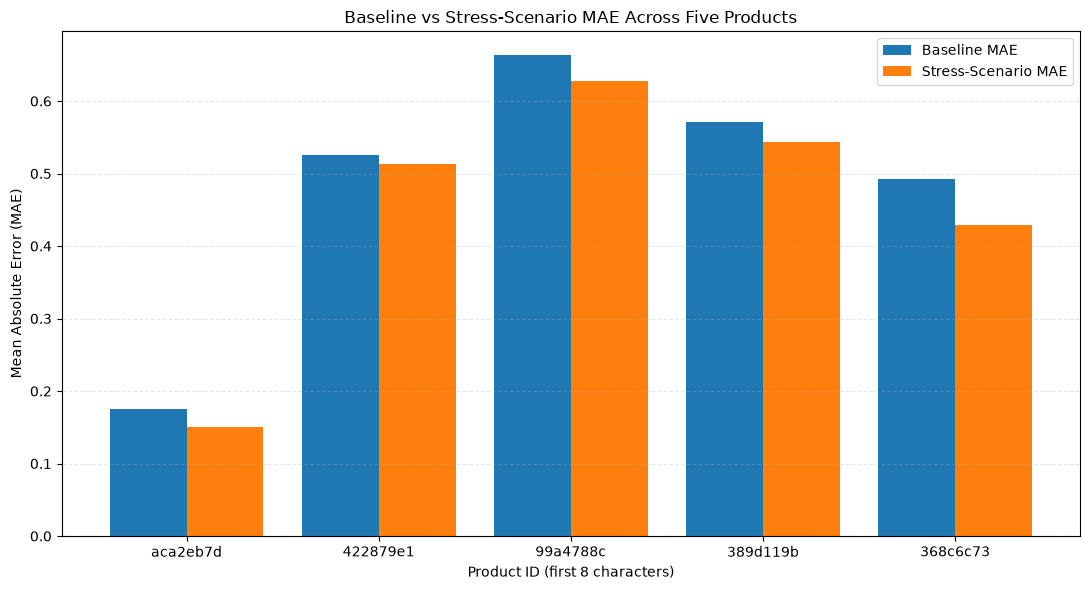

Sensitivity results saved: C:\Users\VICTUS\OneDrive\Documents\GitHub\Olist-E-Commerce-Stockout-Stress-Test\outputs\results\product_sensitivity_check.csv
Sensitivity graph saved: C:\Users\VICTUS\OneDrive\Documents\GitHub\Olist-E-Commerce-Stockout-Stress-Test\outputs\results\product_sensitivity_comparison.png


In [17]:

import matplotlib.pyplot as plt
import pandas as pd

top_products = product_counts.head(5).index.tolist()
sensitivity_results = []

# Last date of the simulated zero-sales window
stockout_end = stockout_dates.max()

for product_id in top_products:
    product_data = sales[sales["product_id"] == product_id]

    product_daily = (
        product_data.groupby("purchase_date")
        .size()
        .reindex(full_dates, fill_value=0)
    )

    product_daily.index.name = "date"

    # Apply the same simulated window
    product_stress = product_daily.copy()
    product_stress.loc[stockout_dates] = 0

    product_baseline_forecast = rolling_mean_forecast(
        product_daily, window=7
    )

    product_stress_forecast = rolling_mean_forecast(
        product_stress, window=7
    )

    # Evaluate over the same test period and dates
    product_eval = pd.DataFrame({
        "actual": product_daily,
        "baseline": product_baseline_forecast,
        "stress": product_stress_forecast
    }).iloc[split_idx:].dropna()

    product_eval["baseline_error"] = (
        product_eval["baseline"] - product_eval["actual"]
    ).abs()

    product_eval["stress_error"] = (
        product_eval["stress"] - product_eval["actual"]
    ).abs()

    # Forecasts during the simulated zero-sales window
    during = product_eval.loc[
        product_eval.index.isin(stockout_dates)
    ]

    # Forecasts after the simulated window
    after = product_eval.loc[
        product_eval.index > stockout_end
    ]

    sensitivity_results.append({
        "product_id": product_id,
        "delivered_item_records": int(product_counts.loc[product_id]),

        "baseline_test_mae": product_eval["baseline_error"].mean(),
        "stress_test_mae": product_eval["stress_error"].mean(),

        "baseline_mean_forecast_during_window":
            during["baseline"].mean(),

        "stress_mean_forecast_during_window":
            during["stress"].mean(),

        "forecast_change_during_window": (
            during["stress"].mean() - during["baseline"].mean()
        ),

        "baseline_mean_forecast_after_window":
            after["baseline"].mean(),

        "stress_mean_forecast_after_window":
            after["stress"].mean(),

        "forecast_change_after_window": (
            after["stress"].mean() - after["baseline"].mean()
        )
    })

# Create and display the results table
sensitivity_df = pd.DataFrame(sensitivity_results)

display(sensitivity_df.round(3))

# Ensure the output folder exists
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Save the CSV results
csv_path = RESULTS_DIR / "product_sensitivity_check.csv"
sensitivity_df.to_csv(csv_path, index=False)

# Create the comparison graph
plot_df = sensitivity_df.copy()
plot_df["product_id"] = plot_df["product_id"].astype(str).str[:8]

ax = plot_df.set_index("product_id")[
    ["baseline_test_mae", "stress_test_mae"]
].plot(
    kind="bar",
    figsize=(11, 6),
    width=0.8
)

ax.set_title("Baseline vs Stress-Scenario MAE Across Five Products")
ax.set_xlabel("Product ID (first 8 characters)")
ax.set_ylabel("Mean Absolute Error (MAE)")
ax.tick_params(axis="x", rotation=0)
ax.legend(["Baseline MAE", "Stress-Scenario MAE"])
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()

# Save the PNG in the existing outputs folder
png_path = RESULTS_DIR / "product_sensitivity_comparison.png"
plt.savefig(png_path, dpi=300, bbox_inches="tight")
plt.show()

print("Sensitivity results saved:", csv_path.resolve())
print("Sensitivity graph saved:", png_path.resolve())


## 14. Findings and Discussion

### Main Findings

- Selected product: aca2eb7d00ea1a7b8ebd4e68314663af
- Simulated zero window: 2018-06-09 00:00:00 to 2018-06-22 00:00:00
- Baseline test MAE: 0.176
- Stress-scenario test MAE: 0.150
- Average forecast change during the window: 0.061
- Average forecast change after the window: 0.090

### Interpretation

The rolling-average forecast uses the previous seven observations.
When recorded values are artificially set to zero, subsequent
forecasts may decrease because some of their inputs are zero.

The size and duration of the change depend on the original activity
pattern, the timing of the simulated window and the forecast window.

### Limitations

1. The dataset does not verify inventory availability.
2. The zero window is simulated, not a confirmed stockout.
3. Daily item-record counts are only a proxy for sales activity.
4. Original recorded activity is used as the evaluation reference;
   it is not a verified measure of lost demand.
5. The 7-day rolling average is a simple baseline rather than a
   comprehensive forecasting model.
6. Results from selected products may not generalise to all products.

### Conclusion

This experiment demonstrates how a simple rolling-average
forecast responds to artificially zero-masked observations.
It illustrates why data-quality and availability context matter
when interpreting sales forecasts. It does not establish actual
stockouts or quantify real lost sales.